# Laboratorio #7 — NLP end-to-end y Embeddings

**CC3092 Deep Learning y Sistemas Inteligentes**

Pipeline completo: texto crudo → tokens → IDs → embeddings (SGNS propio en PyTorch, Word2Vec de gensim,
GloVe preentrenado) → aritmética vectorial → clasificación de AG News.

- **Corpus de embeddings:** WikiText-103 (raw)
- **Clasificación:** AG News (4 clases)
- **Benchmarks:** `questions-words.txt`, `wordsim353.tsv`, `simlex999.txt` (en `data/`)

## 0. Imports y configuración

In [1]:
import re
import time
import json
import pickle
import random
import collections
import io
import contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from gensim.models import Word2Vec, KeyedVectors
import gensim.downloader as api

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA = Path("data")
DATA.mkdir(exist_ok=True)
(DATA / "vectors").mkdir(exist_ok=True)
DEVICE = torch.device("cpu")  # SGNS con tablas sparse: CPU rinde mejor que MPS (gathers pequeños, overhead de kernels)
N_WORKERS = 8                 # hilos para gensim
CORPUS_TOKENS = 20_000_000    # prefijo de WikiText-103 usado como corpus principal (de ~100M)
MIN_COUNT = 5
print("torch", torch.__version__, "| device", DEVICE)

torch 2.14.1 | device cpu


## Fase 1 — Exploración y preprocesamiento

### 1.1 Carga de WikiText-103

El formato *raw* ya viene separado por espacios, con marcas propias: encabezados `= Título =`, y
`@-@`, `@,@`, `@.@` para guiones/comas/puntos dentro de palabras o números. Se limpian al normalizar.

In [2]:
wiki = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
lines = [l for l in wiki["train"]["text"] if l.strip() and not l.lstrip().startswith("=")]  # fuera líneas vacías y encabezados
print(f"{len(wiki['train']):,} líneas totales -> {len(lines):,} párrafos")
print(lines[1][:300])

1,801,350 líneas totales -> 859,532 párrafos
 The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for series newcomers . Character designer Raita Hon


### 1.2 Tokenizador propio vs spaCy vs NLTK

Pipeline propio: minúsculas → resolver marcas `@x@` → regex que separa palabras (con contracciones tipo
`don't`), números y signos de puntuación. Para embeddings se descarta la puntuación y los números se
colapsan a `<num>` (un vector por cada año/cifra solo diluye el vocabulario).

In [3]:
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|\d+(?:[.,]\d+)*|[^\sa-z\d]")
AT_RE = re.compile(r" @(.)@ ")

def tokenize(text, keep_punct=False):
    """texto crudo -> lista de tokens. keep_punct=True mantiene signos (solo para comparar tokenizadores)."""
    text = AT_RE.sub(r"\1", text.lower())  # "1 @,@ 000" -> "1,000", "well @-@ known" -> "well-known"
    toks = WORD_RE.findall(text)
    toks = ["<num>" if t[0].isdigit() else t for t in toks]
    return toks if keep_punct else [t for t in toks if t[0].isalpha() or t == "<num>"]

print(tokenize(lines[1][:200], keep_punct=True))

['the', 'game', 'began', 'development', 'in', '<num>', ',', 'carrying', 'over', 'a', 'large', 'portion', 'of', 'the', 'work', 'done', 'on', 'valkyria', 'chronicles', 'ii', '.', 'while', 'it', 'retained', 'the', 'standard', 'features', 'of', 'the', 'series', ',', 'it', 'also', 'underwent', 'multiple', 'adju']


In [4]:
import spacy
from nltk.tokenize import NLTKWordTokenizer

nlp = spacy.blank("en")  # solo el tokenizador de spaCy, sin modelo (el resto del pipeline no se usa aquí)
nltk_tok = NLTKWordTokenizer()
sample = lines[:3000]

def run(fn):
    t = time.time()
    out = [fn(s) for s in sample]
    return out, time.time() - t

res = {
    "propio (regex)": run(lambda s: tokenize(s, keep_punct=True)),
    "spaCy (blank en)": run(lambda s: [t.text.lower() for t in nlp.make_doc(s)]),
    "NLTK (Treebank)": run(lambda s: [t.lower() for t in nltk_tok.tokenize(AT_RE.sub(r"\1", s))]),
}
rows = []
for name, (toks, secs) in res.items():
    flat = [t for d in toks for t in d]
    rows.append({"tokenizador": name, "tokens": len(flat), "vocab": len(set(flat)),
                 "seg/3000 párrafos": round(secs, 2)})
pd.DataFrame(rows)

,tokenizador,tokens,vocab,seg/3000 párrafos
0,propio (regex),332870,23450,0.04
1,spaCy (blank en),334540,24638,1.09
2,NLTK (Treebank),319911,26614,0.31


In [5]:
ex = "The U.S. president's well-known \"state-of-the-art\" plan costs $1,000.50 -- isn't cheap!"
for name, fn in {"propio": lambda s: tokenize(s, True),
                 "spaCy": lambda s: [t.text for t in nlp.make_doc(s)],
                 "NLTK": nltk_tok.tokenize}.items():
    print(f"{name:7s}", fn(ex))

propio  ['the', 'u', '.', 's', '.', "president's", 'well', '-', 'known', '"', 'state', '-', 'of', '-', 'the', '-', 'art', '"', 'plan', 'costs', '$', '<num>', '-', '-', "isn't", 'cheap', '!']
spaCy   ['The', 'U.S.', 'president', "'s", 'well', '-', 'known', '"', 'state', '-', 'of', '-', 'the', '-', 'art', '"', 'plan', 'costs', '$', '1,000.50', '--', 'is', "n't", 'cheap', '!']
NLTK    ['The', 'U.S.', 'president', "'s", 'well-known', '``', 'state-of-the-art', "''", 'plan', 'costs', '$', '1,000.50', '--', 'is', "n't", 'cheap', '!']


**Observaciones.** Las tres coinciden en lo esencial (palabras y puntuación separadas). Difieren en casos límite:
spaCy conserva `U.S.` y `1,000.50` como un token y separa `'s` y `n't`; Treebank además deja `well-known` y
`state-of-the-art` enteros; el regex propio parte `u.s.` en `u`,`s`, pega `president's` y colapsa números a `<num>`.
El regex es ~25x más rápido que spaCy y ~8x que NLTK. Como WikiText ya viene pre-tokenizado y para embeddings la
diferencia es mínima, se usa el propio. (Costo conocido: el clítico `'s` ya separado por WikiText queda como el token `s`.)

### 1.3 Corpus de entrenamiento (texto → tokens → IDs)

In [6]:
CACHE = DATA / "corpus.pkl"
if CACHE.exists():
    tokens = pickle.load(open(CACHE, "rb"))
else:
    tokens, n = [], 0
    for l in lines:
        t = tokenize(l)
        tokens.extend(t)
        if len(tokens) >= CORPUS_TOKENS:
            break
    tokens = tokens[:CORPUS_TOKENS]
    pickle.dump(tokens, open(CACHE, "wb"))
print(f"{len(tokens):,} tokens | {len(set(tokens)):,} tipos")
counts_all = collections.Counter(tokens)

20,000,000 tokens | 221,106 tipos


### 1.4 Ley de Zipf

Si la frecuencia sigue Zipf, `freq(r) ∝ 1 / r^α` con α≈1: una recta de pendiente ≈ −1 en escala log–log.

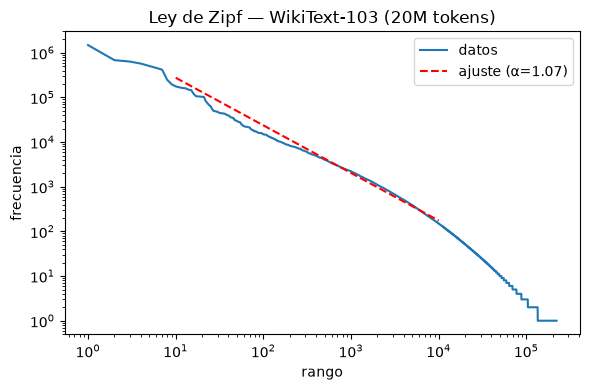

top-10: [('the', 1485833), ('<num>', 683816), ('of', 636502), ('and', 572665), ('in', 506862), ('to', 458448), ('a', 417457), ('was', 247996), ('s', 196451), ('on', 176882)]


In [7]:
freqs = np.array(sorted(counts_all.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
# la cola (frecuencia 1-2) se aplana por discretización; ajustar sobre el rango 10..10^4
sel = (ranks >= 10) & (ranks <= 10_000)
slope, intercept = np.polyfit(np.log(ranks[sel]), np.log(freqs[sel]), 1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ranks, freqs, label="datos")
ax.loglog(ranks[sel], np.exp(intercept) * ranks[sel] ** slope, "r--", label=f"ajuste (α={-slope:.2f})")
ax.set(xlabel="rango", ylabel="frecuencia", title="Ley de Zipf — WikiText-103 (20M tokens)")
ax.legend(); plt.tight_layout(); plt.savefig("zipf.png", dpi=150); plt.show()
print("top-10:", counts_all.most_common(10))

### 1.5 Tamaño del vocabulario vs `min_count`

In [8]:
total = sum(freqs)
rows = []
for mc in [1, 2, 5, 10, 20, 50, 100]:
    keep = freqs >= mc
    rows.append({"min_count": mc, "vocab": int(keep.sum()), "% tipos": round(100 * keep.mean(), 1),
                 "% tokens cubiertos": round(100 * freqs[keep].sum() / total, 2)})
mc_table = pd.DataFrame(rows)
mc_table

,min_count,vocab,% tipos,% tokens cubiertos
0,1,221106,100.0,100.00
1,2,134469,60.8,99.57
2,5,76975,34.8,98.80
3,10,52011,23.5,97.99
4,20,35271,16.0,96.84
5,50,20487,9.3,94.55
6,100,13172,6.0,91.98


La cola larga domina el vocabulario (~65% de los tipos aparece <5 veces) pero cubre una fracción
mínima de los tokens. `min_count=5` conserva ~99% del texto con una fracción del vocabulario: las palabras
más raras no tienen contextos suficientes para aprender un vector útil y solo agrandan la tabla de embeddings.

### 1.6 Vocabulario, IDs y submuestreo de palabras frecuentes

Submuestreo (Mikolov et al., 2013): cada ocurrencia de la palabra `w` se conserva con probabilidad
`P(w) = min(1, sqrt(t / f(w)) + t / f(w))`, con `f` la frecuencia relativa. Las palabras muy frecuentes
(`the`, `of`) aportan poca información por ocurrencia y consumirían la mayor parte del cómputo.

In [9]:
itos = [w for w, c in counts_all.most_common() if c >= MIN_COUNT]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)
ids = np.array([stoi[t] for t in tokens if t in stoi], dtype=np.int32)
cnt = np.array([counts_all[w] for w in itos], dtype=np.float64)
freq = cnt / cnt.sum()
print(f"V={V:,} | corpus en IDs: {len(ids):,}")

SUBSAMPLE_T = 1e-4  # t=1e-5 es lo típico para corpus de miles de millones de tokens; 1e-4 para 20M
def keep_prob(freq, t=SUBSAMPLE_T):
    return np.minimum(1.0, np.sqrt(t / freq) + t / freq)

kp = keep_prob(freq)
exp_kept = (kp[ids]).mean()
print(f"fracción esperada de tokens conservados por época: {exp_kept:.1%}")
print(pd.DataFrame({"palabra": itos[:8], "freq": freq[:8].round(4), "P(conservar)": kp[:8].round(3)}).to_string(index=False))

V=76,975 | corpus en IDs: 19,760,936
fracción esperada de tokens conservados por época: 57.3%
palabra   freq  P(conservar)
    the 0.0752         0.038
  <num> 0.0346         0.057
     of 0.0322         0.059
    and 0.0290         0.062
     in 0.0256         0.066
     to 0.0232         0.070
      a 0.0211         0.074
    was 0.0125         0.097


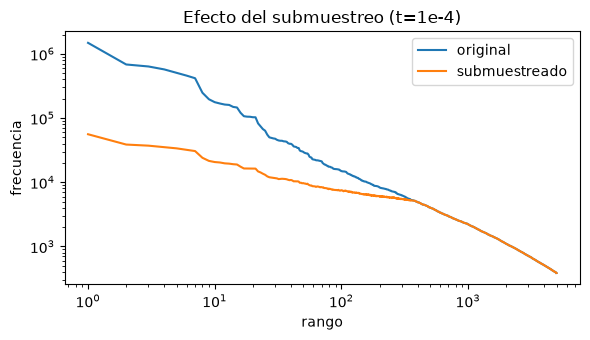

19,760,936 -> 11,318,787 tokens (57.3%); 'the': 1,485,833 -> 55,989


In [10]:
rng = np.random.default_rng(SEED)
sub = ids[rng.random(len(ids)) < kp[ids]]
c0 = np.bincount(ids, minlength=V); c1 = np.bincount(sub, minlength=V)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(np.arange(1, 5001), c0[:5000], label="original")
ax.loglog(np.arange(1, 5001), c1[:5000], label="submuestreado")
ax.set(xlabel="rango", ylabel="frecuencia", title="Efecto del submuestreo (t=1e-4)")
ax.legend(); plt.tight_layout(); plt.savefig("subsampling.png", dpi=150); plt.show()
print(f"{len(ids):,} -> {len(sub):,} tokens ({len(sub)/len(ids):.1%}); 'the': {c0[stoi['the']]:,} -> {c1[stoi['the']]:,}")

## Fase 2 — Construcción y entrenamiento de embeddings

### 2.0 Evaluación: WordSim-353, SimLex-999 y analogías (3CosAdd)

Todos los modelos se exponen como `gensim.KeyedVectors` (misma interfaz para el SGNS propio, gensim y GloVe).

- **Similitud:** correlación de Spearman entre el coseno del modelo y el puntaje humano (pares con OOV se omiten).
- **Analogías:** 3CosAdd propio, `argmax_d cos(d, b) − cos(d, a) + cos(d, c)` excluyendo `a, b, c`, sobre las
  30 000 palabras más frecuentes. Preguntas con alguna palabra fuera de ese vocabulario se omiten (se reporta cobertura).
  Las 5 primeras categorías de `questions-words.txt` son semánticas y las 9 restantes sintácticas.

In [11]:
def load_analogies(path="data/questions-words.txt"):
    sections, cur = {}, None
    for line in open(path):
        if line.startswith(":"):
            cur = line[1:].strip(); sections[cur] = []
        else:
            sections[cur].append(tuple(line.lower().split()))
    return sections

ANALOGIES = load_analogies()
SEM = list(ANALOGIES)[:5]
print(len(ANALOGIES), "categorías;", sum(map(len, ANALOGIES.values())), "preguntas")

def analogy_eval(kv, restrict=30_000, sections=ANALOGIES):
    """3CosAdd. Devuelve dict categoría -> (aciertos, evaluadas, total)."""
    n = min(restrict, len(kv.index_to_key))
    E = torch.from_numpy(kv.vectors[:n]).float()
    E = F.normalize(E, dim=1)
    out = {}
    for name, qs in sections.items():
        idx = [[kv.key_to_index.get(w, n) for w in q] for q in qs]
        idx = torch.tensor([q for q in idx if max(q) < n])
        if len(idx) == 0:
            out[name] = (0, 0, len(qs)); continue
        a, b, c, d = idx.T
        scores = (E[b] - E[a] + E[c]) @ E.T
        scores.scatter_(1, torch.stack([a, b, c], 1), -1e9)  # excluir las palabras de la pregunta
        out[name] = (int((scores.argmax(1) == d).sum()), len(idx), len(qs))
    return out

def analogy_acc(res, names=None):
    names = names or list(res)
    hit = sum(res[n][0] for n in names); tot = sum(res[n][1] for n in names)
    return hit / tot if tot else float("nan")

def evaluate(kv):
    ws = kv.evaluate_word_pairs("data/wordsim353.tsv", dummy4unknown=False)
    sl = kv.evaluate_word_pairs("data/simlex999.txt", dummy4unknown=False)
    an = analogy_eval(kv)
    return {"WS353": ws[1][0], "SimLex": sl[1][0], "ana_total": analogy_acc(an),
            "ana_sem": analogy_acc(an, SEM), "ana_syn": analogy_acc(an, [s for s in an if s not in SEM])}

def to_kv(E, keys):
    kv = KeyedVectors(E.shape[1]); kv.add_vectors(keys, E); return kv

14 categorías; 19544 preguntas


### 2.1 Skip-gram con Negative Sampling desde cero (PyTorch)

Dos tablas `nn.Embedding` (entrada `v_c` y salida `u_o`). Para un par (centro `c`, contexto `o`) y `K` negativos
`n_k ~ P_n(w) ∝ f(w)^0.75`:

`L = −log σ(u_o · v_c) − Σ_k log σ(−u_{n_k} · v_c)`

Decisiones de diseño:
- **Ventana dinámica:** el radio se sortea uniforme en `[1, W]` para cada centro (pesa más a los contextos cercanos, como word2vec).
- **Submuestreo** re-muestreado en cada época (sección 1.6).
- **Tablas `sparse=True` + `SparseAdam`:** en cada paso solo se actualizan las filas usadas (vocab de 77k).
- **Pares generados vectorizados** con numpy (un desplazamiento `d` por pasada), mezclados y servidos en mini-batches de 8192.
- Los vectores finales son la tabla de entrada `v` (como en word2vec).

In [12]:
class SGNS(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.inp = nn.Embedding(V, d, sparse=True)
        self.out = nn.Embedding(V, d, sparse=True)
        nn.init.uniform_(self.inp.weight, -0.5 / d, 0.5 / d)
        nn.init.zeros_(self.out.weight)

    def forward(self, c, o, neg):
        v = self.inp(c)                                         # B,d
        pos = F.logsigmoid((v * self.out(o)).sum(-1))           # B
        negs = F.logsigmoid(-torch.bmm(self.out(neg), v.unsqueeze(-1)).squeeze(-1)).sum(-1)  # B,K -> B
        return -(pos + negs).mean()


def make_pairs(ids, keep, window, rng):
    """Una época de pares (centro, contexto): submuestreo + ventana dinámica."""
    s = ids[rng.random(len(ids)) < keep[ids]]
    b = rng.integers(1, window + 1, len(s))
    C, O = [], []
    for d in range(1, window + 1):
        m = b[:-d] >= d;  C.append(s[:-d][m]); O.append(s[d:][m])      # contexto a la derecha
        m = b[d:] >= d;   C.append(s[d:][m]);  O.append(s[:-d][m])     # contexto a la izquierda
    C, O = np.concatenate(C), np.concatenate(O)
    p = rng.permutation(len(C))
    return torch.from_numpy(C[p]).long(), torch.from_numpy(O[p]).long()


def train_sgns(tag, dim=100, window=5, neg=5, epochs=3, lr=3e-3, batch=8192, ids=ids, verbose=True):
    path = DATA / "vectors" / f"{tag}.kv"
    if path.exists():
        return KeyedVectors.load(str(path))
    rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
    model = SGNS(V, dim).to(DEVICE)
    opt = torch.optim.SparseAdam(model.parameters(), lr=lr)
    noise = torch.from_numpy(cnt ** 0.75); cdf = (noise / noise.sum()).cumsum(0).float()
    for ep in range(epochs):
        C, O = make_pairs(ids, kp, window, rng)
        n_steps = len(C) // batch; t0 = time.time(); run = 0.0
        for i in range(n_steps):
            lr_now = lr * max(0.05, 1 - (ep + i / n_steps) / epochs)  # decaimiento lineal global
            for g in opt.param_groups: g["lr"] = lr_now
            sl = slice(i * batch, (i + 1) * batch)
            negs = torch.searchsorted(cdf, torch.rand(batch, neg)).clamp_(max=V - 1)  # ~ f^0.75
            loss = model(C[sl].to(DEVICE), O[sl].to(DEVICE), negs.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            run += loss.item() if i % 50 == 0 else 0
        kv = to_kv(model.inp.weight.detach().cpu().numpy(), itos)
        if verbose:
            print(f"[{tag}] ep {ep+1}/{epochs} | {len(C):,} pares | loss~{run/(n_steps/50):.3f} | "
                  f"{time.time()-t0:.0f}s | {({k: round(v, 3) for k, v in evaluate(kv).items()})}")
    kv.save(str(path)); return kv

sgns = train_sgns("sgns_w5")

### 2.2 Word2Vec de gensim (referencia)

Mismo corpus, mismos hiperparámetros (`sg=1`, `dim=100`, `window=5`, `negative=5`, `sample=1e-4`, `min_count=5`,
3 épocas). Si el SGNS propio está bien implementado, debe quedar cerca de gensim.

In [13]:
def sentences(toks, size=1000):
    return [toks[i:i + size] for i in range(0, len(toks), size)]

def train_gensim(tag, toks=None, vector_size=100, window=5, negative=5, alpha=0.025, epochs=3, sg=1, sample=SUBSAMPLE_T, save=False):
    path = DATA / "vectors" / f"{tag}.kv"
    if path.exists():
        return KeyedVectors.load(str(path))
    with contextlib.redirect_stderr(io.StringIO()):  # gensim imprime 'Exception ignored in our_dot_float' (scipy BLAS), inocuo
      m = Word2Vec(sentences(tokens if toks is None else toks), vector_size=vector_size, window=window, negative=negative,
                   alpha=alpha, epochs=epochs, sg=sg, sample=sample, min_count=MIN_COUNT, workers=N_WORKERS, seed=SEED)
    if save: m.wv.save(str(path))
    return m.wv

t0 = time.time()
w2v = train_gensim("gensim_w5", save=True)
print(f"gensim: {len(w2v):,} palabras en {time.time()-t0:.0f}s")

gensim: 76,975 palabras en 21s


### 2.3 GloVe preentrenado (`glove-wiki-gigaword-100`, sin entrenamiento adicional)

In [14]:
glove = api.load("glove-wiki-gigaword-100")
print(glove.vectors.shape)

(400000, 100)


### 2.4 Comparación de los tres modelos

In [15]:
models = {"SGNS propio (PyTorch)": sgns, "Word2Vec gensim": w2v, "GloVe 100d (preentrenado)": glove}
cmp = pd.DataFrame({k: evaluate(v) for k, v in models.items()}).T
cmp.insert(0, "vocab", [len(v.index_to_key) for v in models.values()])
cmp.round(3)

,vocab,WS353,SimLex,ana_total,ana_sem,ana_syn
SGNS propio (PyTorch),76975,0.632,0.292,0.330,0.250,0.367
Word2Vec gensim,76975,0.619,0.305,0.313,0.209,0.362
GloVe 100d (preentrenado),400000,0.533,0.296,0.655,0.655,0.655
